In [1]:
# Imports
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from matplotlib import pyplot as plt

from utils import Binarize, Flatten

from hopfield import Hopfield

## Create Data Loaders

In [ ]:
# Download the MNIST dataset

transform = transforms.Compose([Binarize(), transforms.ToTensor(), Flatten()])
mnist_train_dataset = datasets.MNIST(root='/home/savio/Documents/modeling_generation/data', train=True, download=True, transform=transform)
mnist_eval_dataset = datasets.MNIST(root='/home/savio/Documents/modeling_generation/data', train=False, download=True, transform=transform)

Label: 3
Image shape: torch.Size([784])


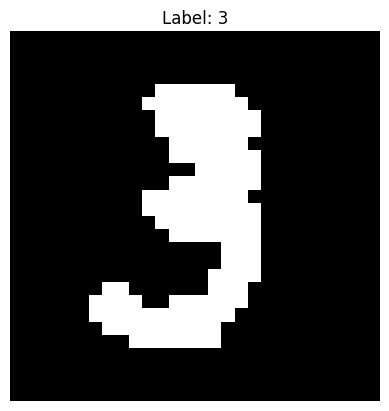

Unique pixel values: tensor([-1.,  1.])


In [3]:
# Get a sample image from the dataset
sample_image, label = mnist_train_dataset[10]
print(f"Label: {label}")
print(f"Image shape: {sample_image.shape}")

# Reshape the image to a 28x28 image and display it
plt.imshow(sample_image.view(28, 28), cmap='gray')
plt.title(f"Label: {label}")
plt.axis('off')
plt.show()

print(f"Unique pixel values: {torch.unique(sample_image)}")

In [4]:
# Create train and test dataloaders
train_dataloader = torch.utils.data.DataLoader(mnist_train_dataset, batch_size=1, shuffle=True)
eval_dataloader = torch.utils.data.DataLoader(mnist_eval_dataset, batch_size=1, shuffle=False)

In [5]:
# Instantiate the Hopfield network
hpf_model = Hopfield(input_size=28*28, threshold=0.0, max_iter=100)

In [11]:
# Train the Hopfield network on the training dataset

selected_labels = [0, 2, 4, 6, 8]  # Select the first 5 classes for training
samples_per_label = 20  # Number of samples to use per label for training

label_counts = {label: 0 for label in selected_labels}  # Initialize label counts

from tqdm import tqdm

# Zero out the weight matrix before training
hpf_model.weight_matrix.zero_()

sample_count = 0
for data, label in tqdm(train_dataloader, desc='Train Loop'):

    if label.item() not in selected_labels:
        continue  # Skip samples that are not in the selected labels

    if label_counts[label.item()] >= samples_per_label:
        continue  # Skip if we have already used enough samples for this label

    label_counts[label.item()] += 1  # Increment the count for this label

    # Squeeze the data to remove the batch dimension
    data = data.squeeze(0)
    
    # Get the outer product of the data sample with itself. 
    # This is equaivalent to computing the product of each neuron state with every other neuron state.
    # If a pair of states is the same, we strengthen the connection between those neurons. 
    # If they are different, we weaken the connection. 
    # With the states being bipolar, the product will be +1 if the states are the same and -1 if they are different.
    # So to update the weight matrix, we can simply add the outer product of the current sample with itself to the weight matrix.
    hpf_model.weight_matrix += torch.outer(data, data)

    sample_count += 1

# After training on all samples, we need to divide the weight matrix by the number of samples to get the average weight matrix.
hpf_model.weight_matrix /= sample_count

# Subtract all the diagonal elements of the weight matrix from the weight matrix to ensure that there are no self-connections in the network.
hpf_model.weight_matrix -= torch.diag(torch.diag(hpf_model.weight_matrix))

print("Training complete. Number of samples used for training:", sample_count)

Train Loop: 100%|██████████| 60000/60000 [00:03<00:00, 19457.13it/s]

Training complete. Number of samples used for training: 100


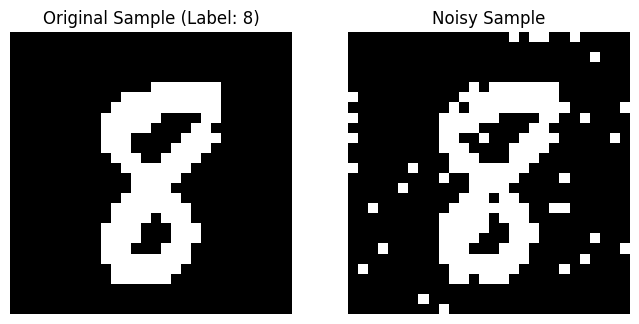

In [17]:
# Test the Hopfield network on a single random sample from the evaluation dataset

# Get a random sample from the evaluation dataset
random_index = torch.randint(0, len(eval_dataloader.dataset), (1,)).item()

while eval_dataloader.dataset[random_index][1] not in selected_labels:
    random_index = torch.randint(0, len(eval_dataloader.dataset), (1,)).item()
    
test_sample, test_label = eval_dataloader.dataset[random_index]

# Add some noise to the test sample by flipping some of the bipolar values. We can do this by randomly selecting some indices and multiplying the values at those indices by -1.
percent_noisy_bits = 0.05  # Percentage of bits to flip
num_noisy_bits = int(percent_noisy_bits * test_sample.size(0))
noisy_indices = torch.randperm(test_sample.size(0))[:num_noisy_bits]
noisy_test_sample = test_sample.clone()
noisy_test_sample[noisy_indices] *= -1

# Visualize the original and noisy test samples
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(test_sample.view(28, 28), cmap='gray')
axes[0].set_title(f"Original Sample (Label: {test_label})")
axes[0].axis('off')

axes[1].imshow(noisy_test_sample.view(28, 28), cmap='gray')
axes[1].set_title("Noisy Sample")
axes[1].axis('off')
plt.show()

Converged to local energy minimum after 3 iterations.


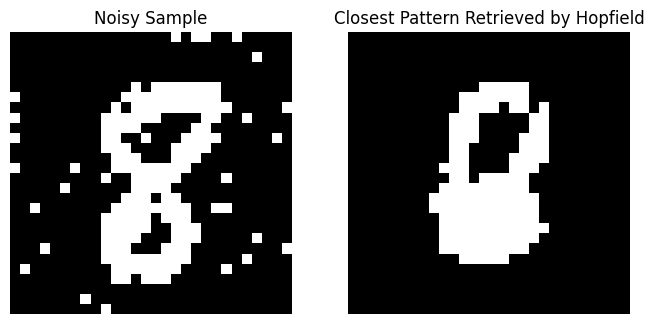

In [18]:
# Pass in the noisy sample to the Hopfield network and let it evolve until convergence.

hpf_model.eval()  # Set the model to evaluation mode

with torch.no_grad():
    closest_pattern = hpf_model.forward(noisy_test_sample)


# Visualize the closest pattern along with the noisy sample retrieved by the Hopfield network

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(noisy_test_sample.view(28, 28), cmap='gray')
axes[0].set_title("Noisy Sample")
axes[0].axis('off') 

axes[1].imshow(closest_pattern.view(28, 28), cmap='gray')
axes[1].set_title("Closest Pattern Retrieved by Hopfield")
axes[1].axis('off')
plt.show()